In [1]:
import quarters_clean

In [3]:
gdp_df = quarters_clean.pd.read_parquet("../parquet_exports/gdp_values.parquet")

In [5]:
gdp_df.head()

,Quarter,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,...,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay
0,1,1960,3.93,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,49.06,NaN,NaN,NaN,NaN,NaN,135.83,6.43,NaN
1,2,1960,4.18,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,67.98,NaN,NaN,NaN,NaN,NaN,135.68,6.48,NaN
2,3,1960,4.34,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,61.00,NaN,NaN,NaN,NaN,NaN,136.50,6.58,NaN
3,4,1960,4.87,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,71.79,NaN,NaN,NaN,NaN,NaN,135.28,6.71,NaN
4,1,1961,4.23,NaN,NaN,NaN,NaN,9.51,NaN,NaN,...,NaN,61.95,NaN,NaN,NaN,NaN,NaN,136.48,6.88,NaN


In [6]:
gdp_df.tail()

,Quarter,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,...,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay
257,2,2024,678.35,120.93,154.65,2921.23,48.14,753.92,75091.54,32883.76,...,1827.69,636205.4,400.31,1618.85,206.50,4520.55,9920.84,7254.18,699.17,81953.81
258,3,2024,676.79,119.00,147.88,2989.91,53.77,800.82,75344.20,34175.80,...,1859.09,643531.6,393.31,1548.65,206.60,4615.84,11915.59,7343.73,716.05,80770.75
259,4,2024,715.14,126.77,163.78,3080.37,57.59,798.84,84662.46,37372.62,...,1928.18,668933.8,420.44,1698.81,210.09,4823.23,12704.05,7430.98,735.14,89086.69
260,1,2025,675.42,119.38,152.24,3019.58,45.62,757.58,82042.34,31875.80,...,1798.80,622771.1,397.66,1552.81,207.83,4744.03,12125.17,7490.50,744.73,92478.27
261,2,2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,423.04,NaN,NaN,NaN,NaN,7582.78,NaN,NaN


In [7]:
quarters_clean.summarize_missing_by_country(gdp_df)

,Missing Count,Missing %
Malaysia,189,72.14
Morocco,182,69.47
India,178,67.94
Macedonia,161,61.45
Colombia,161,61.45
Turkey,153,58.40
Brazil,145,55.34
Russia,143,54.58
Bulgaria,141,53.82
Croatia,141,53.82


**H1)** The previous output indicates that Malaysia will be the country that will most restrict us in the time range available to perform the correlation analysis. This statement is only correct due to the process of extracting and joining the values of this indicator. If indicators were downloaded for a country and those values were not available for a time range already existing in the master data frame, NaN values were assigned.

In [8]:
missing_entries = quarters_clean.get_missing_entries(gdp_df)
missing_entries.head()

,Quarter,Year,Country,Value
0,1,1960,Austria,NaN
1,1,1960,Belgium,NaN
2,1,1960,Brazil,NaN
3,1,1960,Bulgaria,NaN
4,1,1960,Canada,NaN


In [9]:
malaysia_missing = quarters_clean.clean_country_missing_entries(missing_entries, "Malaysia")
malaysia_missing

,Quarter,Year,Country,Value
0,1,1960,Malaysia,NaN
1,2,1960,Malaysia,NaN
2,3,1960,Malaysia,NaN
3,4,1960,Malaysia,NaN
4,1,1961,Malaysia,NaN
...,...,...,...,...
184,1,2006,Malaysia,NaN
185,2,2006,Malaysia,NaN
186,3,2006,Malaysia,NaN
187,4,2006,Malaysia,NaN


The previous outputs show us that Malaysia has no values for the gdp from 1960 to 2006 nor for 2025. Consequently, it has values in the range from 2008 to 2024, a desirable range since other values which we extracted with the crawlers are defined between 2014 and 2023.

### Let's delete all the data from the beginning until 2010

In [12]:
clean_df1 = gdp_df.copy()

In [13]:
clean_df1 = quarters_clean.filter_by_year(clean_df1, min_year=2006, max_year=2024, exclude_years=[2025])
clean_df1.head()

,Quarter,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,...,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay
0,1,2007,264.95,66.88,82.91,631.42,13.04,371.45,20699.14,5715.93,...,536.81,252586.3,256.66,784.50,141.77,2258.18,191.19,3558.30,374.22,20896.72
1,2,2007,279.50,70.69,86.74,670.65,14.77,391.49,22185.49,6478.16,...,558.09,268345.3,273.25,844.15,146.92,2187.39,214.34,3605.58,378.22,21239.17
2,3,2007,284.84,70.54,83.63,691.85,17.54,409.24,20906.31,6948.21,...,570.71,275865.8,261.43,793.20,148.20,2236.01,239.21,3642.43,392.02,22425.91
3,4,2007,304.66,74.09,90.34,726.34,18.14,405.48,22058.84,7866.93,...,621.74,292862.8,286.20,890.29,152.20,2394.71,242.98,3671.33,400.17,25304.25
4,1,2008,285.03,69.63,85.78,712.06,14.90,389.66,22074.36,6937.36,...,610.23,271693.8,268.48,818.52,149.46,2448.50,219.84,3667.10,395.40,25806.45


In [14]:
clean_df1.tail()

,Quarter,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,...,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay
67,4,2023,690.21,122.28,158.09,2865.30,53.18,764.41,75383.79,35722.48,...,1840.02,635747.1,396.07,1626.25,204.08,4638.67,8527.68,7074.25,693.21,83109.55
68,1,2024,651.03,117.53,147.67,2753.20,43.36,718.77,76532.68,30476.18,...,1725.42,608186.6,377.57,1526.04,202.25,4623.05,8870.04,7156.03,700.63,84303.14
69,2,2024,678.35,120.93,154.65,2921.23,48.14,753.92,75091.54,32883.76,...,1827.69,636205.4,400.31,1618.85,206.50,4520.55,9920.84,7254.18,699.17,81953.81
70,3,2024,676.79,119.00,147.88,2989.91,53.77,800.82,75344.20,34175.80,...,1859.09,643531.6,393.31,1548.65,206.60,4615.84,11915.59,7343.73,716.05,80770.75
71,4,2024,715.14,126.77,163.78,3080.37,57.59,798.84,84662.46,37372.62,...,1928.18,668933.8,420.44,1698.81,210.09,4823.23,12704.05,7430.98,735.14,89086.69


In [15]:
quarters_clean.summarize_missing_by_country(clean_df1)

,Missing Count,Missing %
Russia,1,1.39
Australia,0,0.00
Belgium,0,0.00
Brazil,0,0.00
Bulgaria,0,0.00
Canada,0,0.00
Chile,0,0.00
China,0,0.00
Colombia,0,0.00
Austria,0,0.00


In [16]:
clean_df1["Russia"] = clean_df1["Russia"].ffill()

In [17]:
quarters_clean.summarize_missing_by_country(clean_df1)

,Missing Count,Missing %
Australia,0,0.0
Austria,0,0.0
Belgium,0,0.0
Brazil,0,0.0
Bulgaria,0,0.0
Canada,0,0.0
Chile,0,0.0
China,0,0.0
Colombia,0,0.0
Croatia,0,0.0


In [18]:
clean_df2 = clean_df1.copy()

In [19]:
clean_df2 = quarters_clean.average_by_year(clean_df2)
clean_df2.head()

   Year  Australia  Austria  Belgium     Brazil  Bulgaria    Canada  \
0  2007   283.4875  70.5500  85.9050   680.0650   15.8725  394.4150   
1  2008   309.1825  72.9600  87.9375   777.4525   18.2150  414.2600   
2  2009   315.9400  71.5675  86.9325   833.2600   18.2950  392.8350   
3  2010   341.5600  73.5125  90.8100   971.4625   18.7225  416.5125   
4  2011   367.2525  77.0425  94.6875  1094.0925   20.2800  443.5150   

        Chile       China   Colombia  ...  South-Africa  South-Korea  \
0  21462.4450   6752.3075  107126.50  ...      571.8375    272415.05   
1  22301.3725   7981.1125  119138.50  ...      652.4600    288554.15   
2  22554.8825   8712.9425  125393.50  ...      691.1775    301336.95   
3  27694.4675  10302.9800  136015.00  ...      757.1800    330652.80   
4  30377.3275  12198.5025  154755.75  ...      837.9275    347234.30   

      Spain    Sweden  Switzerland   Thailand    Turkey        USA  \
0  269.3850  828.0350     147.2725  2269.0725  221.9300  3619.4100   


,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,...,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom,Paraguay
0,2007,283.4875,70.5500,85.9050,680.0650,15.8725,394.4150,21462.4450,6752.3075,107126.50,...,571.8375,272415.05,269.3850,828.0350,147.2725,2269.0725,221.9300,3619.4100,386.1575,22466.5125
1,2008,309.1825,72.9600,87.9375,777.4525,18.2150,414.2600,22301.3725,7981.1125,119138.50,...,652.4600,288554.15,278.1075,847.9675,153.6000,2426.7325,250.6900,3679.6450,398.4000,26850.8950
2,2009,315.9400,71.5675,86.9325,833.2600,18.2950,392.8350,22554.8825,8712.9425,125393.50,...,691.1775,301336.95,268.2475,831.0350,150.7600,2414.6650,251.5925,3604.6850,387.2025,27757.7350
3,2010,341.5600,73.5125,90.8100,971.4625,18.7225,416.5125,27694.4675,10302.9800,136015.00,...,757.1800,330652.80,269.2875,887.8800,156.1375,2702.0350,291.9175,3741.1025,402.1400,32273.2200
4,2011,367.2525,77.0425,94.6875,1094.0925,20.2800,443.5150,30377.3275,12198.5025,154755.75,...,837.9275,347234.30,267.1725,926.2050,158.9350,2826.7250,351.2325,3879.4850,415.6475,35371.6125


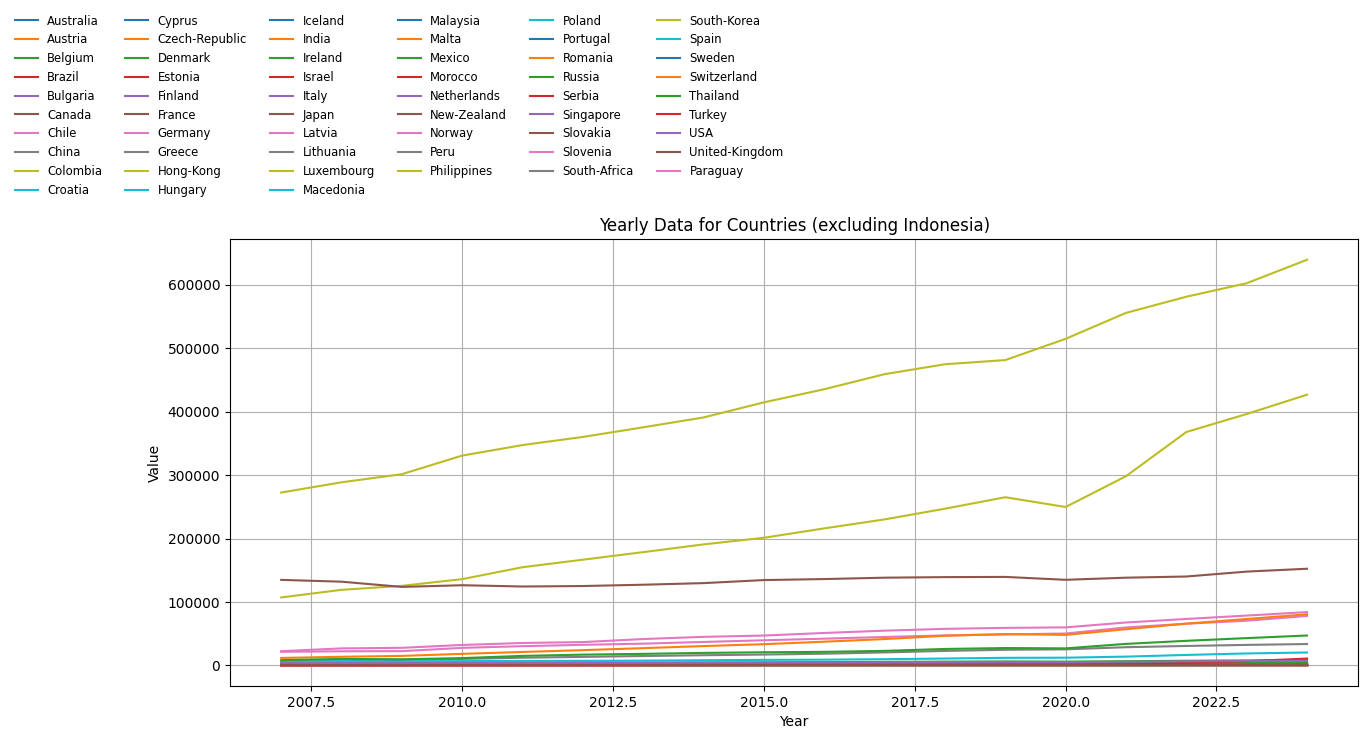

In [24]:
quarters_clean.plot_countries(clean_df2, exclude_country="Indonesia", legend_columns=6)

In [25]:
clean_df2.to_parquet("../data/clean_gdp.parquet", index=False)